# Job Advertisement Category Classification

**Natural Language Processing (CSC4233) — Midterm Project**

This project predicts the category of a job advertisement from its title and description. It compares basic text preprocessing, BoW, TF-IDF and average Word2Vec, then tests Naive Bayes and Logistic Regression.

## 1. Problem and dataset

The aim is to sort job advertisements into six broad groups. This could help a job website organise vacancies.

The notebook uses the first **15,000 rows** from the supplied SEEK job-advertisement dataset. The target labels are IT, Finance, Marketing, Education, Engineering and Other.

**Dataset source:** [GitHub CSV](https://raw.githubusercontent.com/Salehinss/Natural_Language_Process_Project/refs/heads/main/dataset/jobs.csv)

**Licence:** I could not confirm an academic-use licence from the information supplied with the dataset. Please check the original repository or ask its owner for written permission before submitting the project.

## 2. Install and import libraries

Install Gensim for Word2Vec. The remaining libraries are used for data handling, plots and machine learning.

In [1]:
!pip install -q gensim

Set the random seed to 42 so the data split and Word2Vec training can be repeated.

In [2]:
import html
import random
import re
import sys
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import gensim

from IPython.display import display
from nltk.stem import PorterStemmer
from gensim.models import Word2Vec

from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)
from threadpoolctl import threadpool_limits

# Use one seed for all random steps.
SEED = 42
MAX_ROWS = 15000
random.seed(SEED)
np.random.seed(SEED)
threadpool_limits(limits=1)

print("Python:", sys.version.split()[0])
print("pandas:", pd.__version__)
print("scikit-learn:", sklearn.__version__)
print("gensim:", gensim.__version__)
print("Random seed:", SEED)

/home/oai/.config/matplotlib is not a writable directory
Matplotlib created a temporary cache directory at /tmp/matplotlib-291hpzkx because there was an issue with the default path (/home/oai/.config/matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.
Python: 3.13.5
pandas: 2.2.3
scikit-learn: 1.8.0
gensim: 4.4.0
Random seed: 42


## 3. Load and prepare the data

Load no more than 15,000 rows. Join each job title and description, map the original categories to six labels, and remove empty or duplicate text.

In [3]:
DATA_URL = "https://raw.githubusercontent.com/Salehinss/Natural_Language_Process_Project/refs/heads/main/dataset/jobs.csv"

# Load the public dataset first. Use the included CSV backup if the link is unavailable.
try:
    raw_df = pd.read_csv(DATA_URL, nrows=MAX_ROWS)
    data_source = DATA_URL
except Exception:
    try:
        raw_df = pd.read_csv("jobs_first_15000_rows.csv", nrows=MAX_ROWS)
        data_source = "Local 15,000-row CSV backup"
    except FileNotFoundError:
        raw_df = pd.read_csv("jobs.csv", nrows=MAX_ROWS)
        data_source = "Local jobs.csv backup"

raw_df = raw_df.copy()
raw_df["source_row_id"] = raw_df.index

print("Data source:", data_source)
print("Rows loaded:", len(raw_df))
print("Columns:", raw_df.columns.tolist())
display(raw_df.head(3))

,category,city,company_name,geo,job_board,job_description,job_title,job_type,post_date,salary_offered,state,url,source_row_id
0,Retail & Consumer Products,Sydney,Frontline Executive Retail Sydney,AU,seek,Have you had 10 years experience in fresh pro...,Store Manager - Fresh Produce,Full Time,2018-04-15T23:13:45Z,$100k Base + Super + Benefits,North Shore & Northern Beaches,https://www.seek.com.au/job/35989382,0
1,Government & Defence,Brisbane,Powerlink,AU,seek,The Opportunity: The Client Solution Analyst ...,Client Solution Analyst,Full Time,2018-04-15T23:04:40Z,Excellent remuneration packages,Northern Suburbs,https://www.seek.com.au/job/35989272,1
2,Trades & Services,Sydney,Richard Jay Laundry,AU,seek,An innovative business development role for a...,Service Technician / Installer - NSW,Full Time,2018-04-15T23:04:31Z,NaN,Parramatta & Western Suburbs,https://www.seek.com.au/job/35989270,2


Data source: Local 15,000-row CSV backup
Rows loaded: 15000
Columns: ['category', 'city', 'company_name', 'geo', 'job_board', 'job_description', 'job_title', 'job_type', 'post_date', 'salary_offered', 'state', 'url', 'source_row_id']


Map the source categories to the six project labels. Categories outside the five named groups are placed in `Other`.

In [4]:
category_map = {
    "Information & Communication Technology": "IT",
    "Banking & Financial Services": "Finance",
    "Accounting": "Finance",
    "Marketing & Communications": "Marketing",
    "Education & Training": "Education",
    "Engineering": "Engineering"
}
class_order = ["IT", "Finance", "Marketing", "Education", "Engineering", "Other"]

# Check that the columns needed for this project are present.
required_columns = ["category", "job_title", "job_description"]
for column in required_columns:
    if column not in raw_df.columns:
        raise ValueError("Missing required column: " + column)

df = raw_df.copy()
df["label"] = df["category"].map(category_map).fillna("Other")
df["job_title"] = df["job_title"].fillna("").astype(str)
df["job_description"] = df["job_description"].fillna("").astype(str)

# Use both the title and description as the document.
df["text"] = (df["job_title"].str.strip() + " " + df["job_description"].str.strip()).str.strip()

empty_count = (df["text"] == "").sum()
df = df[df["text"] != ""].copy()

duplicate_count = df.duplicated(subset="text").sum()
df = df.drop_duplicates(subset="text", keep="first").reset_index(drop=True)

print("Empty documents removed:", empty_count)
print("Duplicate documents removed:", duplicate_count)
print("Documents left:", len(df))
print("Number of classes:", df["label"].nunique())

assert len(raw_df) <= MAX_ROWS
assert len(df) >= 2000
assert df["label"].nunique() >= 2

display(df["label"].value_counts().reindex(class_order, fill_value=0).to_frame("documents"))

,documents
label,
IT,1309
Finance,1055
Marketing,327
Education,572
Engineering,359
Other,10211


Empty documents removed: 1
Duplicate documents removed: 1166
Documents left: 13833
Number of classes: 6


## 4. Exploratory data analysis

The next cells show the class balance, document length and common words in each class.

### 4.1 Class distribution

Count the documents in each class. The ratio compares the largest class with the smallest.

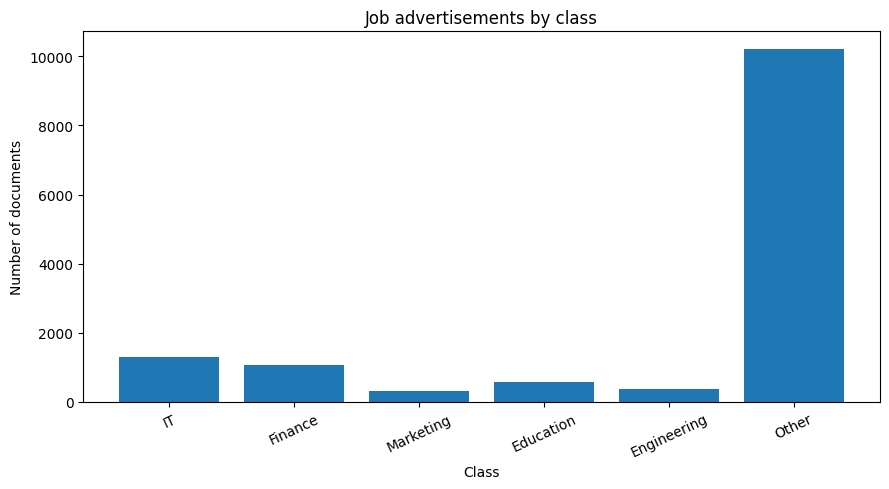

,documents,percentage
label,,
IT,1309,9.46
Finance,1055,7.63
Marketing,327,2.36
Education,572,4.14
Engineering,359,2.60
Other,10211,73.82


Largest-to-smallest class ratio: 31.23 : 1
Interpretation: the classes are strongly imbalanced. Other is the largest class.


In [5]:
class_counts = df["label"].value_counts().reindex(class_order, fill_value=0)
class_percentages = (class_counts / len(df) * 100).round(2)
imbalance_ratio = class_counts.max() / class_counts[class_counts > 0].min()

plt.figure(figsize=(9, 5))
plt.bar(class_counts.index, class_counts.values)
plt.title("Job advertisements by class")
plt.xlabel("Class")
plt.ylabel("Number of documents")
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

display(pd.DataFrame({
    "documents": class_counts,
    "percentage": class_percentages
}))

print("Largest-to-smallest class ratio:", round(imbalance_ratio, 2), ": 1")
print(
    "Interpretation: the classes are strongly imbalanced. "
    + class_counts.idxmax() + " is the largest class."
)

### 4.2 Document length

Count the words in each job advertisement and show the length distribution.

,count,mean,median,min,max
label,,,,,
IT,1309,304.7,277.0,2,1451
Finance,1055,297.1,276.0,2,835
Marketing,327,349.7,341.0,2,954
Education,572,499.6,400.5,1,2257
Engineering,359,321.8,295.0,2,999
Other,10211,278.7,261.0,1,1465


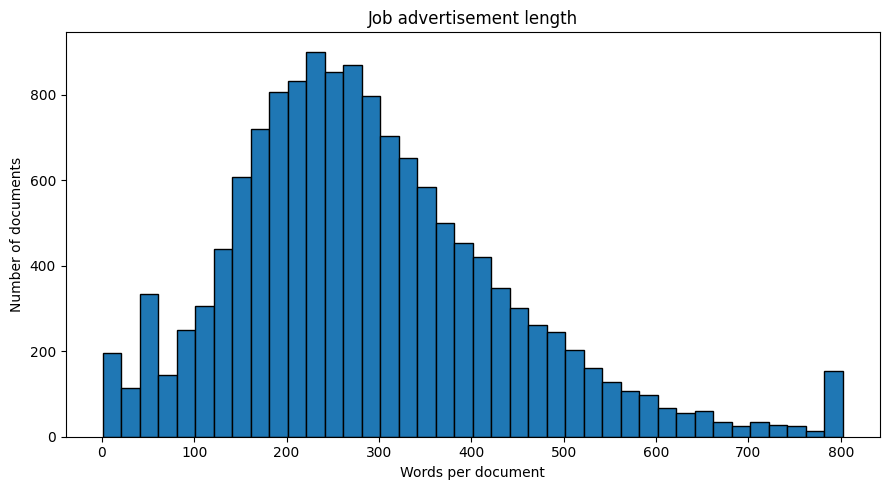

Interpretation: the median advertisement has 271 words.


In [6]:
df["document_length"] = df["text"].str.split().str.len()

length_summary = df.groupby("label")["document_length"].agg(
    ["count", "mean", "median", "min", "max"]
).reindex(class_order).round(1)
display(length_summary)

# Cap the chart at the 99th percentile so very long ads do not hide the main pattern.
length_limit = df["document_length"].quantile(0.99)

plt.figure(figsize=(9, 5))
plt.hist(df["document_length"].clip(upper=length_limit), bins=40, edgecolor="black")
plt.title("Job advertisement length")
plt.xlabel("Words per document")
plt.ylabel("Number of documents")
plt.tight_layout()
plt.show()

print("Interpretation: the median advertisement has", int(df["document_length"].median()), "words.")

### 4.3 Common words before preprocessing

List the 12 most common words in each class before cleaning.

In [7]:
def get_frequent_words(data, text_column, top_n=12):
    word_counts = {}
    for label in class_order:
        text = " ".join(data.loc[data["label"] == label, text_column].astype(str)).lower()
        words = re.findall(r"[a-z]+", text)
        word_counts[label] = Counter(words).most_common(top_n)
    return word_counts

df["raw_lower"] = df["text"].str.lower()
raw_top_words = get_frequent_words(df, "raw_lower")

for label in class_order:
    print("\n", label, "— before preprocessing")
    print(raw_top_words[label])


 IT — before preprocessing
[('and', 21376), ('to', 12381), ('the', 11786), ('of', 8656), ('a', 8354), ('in', 7319), ('with', 5882), ('for', 4958), ('experience', 4766), ('you', 4228), ('will', 3196), ('be', 3043)]

 Finance — before preprocessing
[('and', 15583), ('to', 10791), ('the', 10049), ('a', 8364), ('of', 6604), ('in', 5657), ('with', 4499), ('you', 4333), ('for', 4060), ('will', 3553), ('be', 2948), ('is', 2703)]

 Marketing — before preprocessing
[('and', 6733), ('the', 3830), ('to', 3799), ('a', 2802), ('of', 2372), ('in', 2100), ('with', 1706), ('for', 1546), ('you', 1504), ('marketing', 1495), ('will', 1089), ('experience', 943)]

 Education — before preprocessing
[('and', 15852), ('the', 11850), ('to', 9784), ('of', 7278), ('a', 6041), ('in', 5342), ('for', 3402), ('with', 3262), ('is', 2883), ('school', 2159), ('are', 2047), ('you', 1955)]

 Engineering — before preprocessing
[('and', 6121), ('the', 3776), ('to', 3654), ('a', 2796), ('of', 2601), ('in', 2374), ('with', 

## 5. Preprocessing

The function removes HTML, URLs, emoji, numbers and punctuation. It then lowercases and tokenises the text. Stop-word removal and stemming are optional so they can be compared.

In [8]:
stop_words = set(ENGLISH_STOP_WORDS)
stemmer = PorterStemmer()

def preprocess(text, remove_stop=False, use_stem=False):
    text = html.unescape(str(text))

    # Remove HTML, URLs, emoji and numbers.
    text = re.sub(r"<[^>]+>", " ", text)
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)
    text = re.sub(r"[\U0001F300-\U0001FAFF\U0001F1E0-\U0001F1FF]", " ", text)
    text = re.sub(r"\d+", " ", text)

    # Keep English letters and spaces.
    text = re.sub(r"[^a-zA-Z\s]", " ", text)
    text = text.lower()

    # Split the text into word tokens.
    words = re.findall(r"[a-z]+", text)

    if remove_stop:
        words = [word for word in words if word not in stop_words]

    if use_stem:
        words = [stemmer.stem(word) for word in words]

    return " ".join(words)

# Check that the main cleaning steps work.
sample_text = "<b>Python</b> https://example.com www.example.org 2026 😀 Hiring!"
print("Before:", sample_text)
print("After :", preprocess(sample_text, remove_stop=False, use_stem=False))

Before: <b>Python</b> https://example.com www.example.org 2026 😀 Hiring!
After : python hiring


### 5.1 Train, validation and test split

Use the same stratified 70/15/15 split for every experiment. The test set stays separate until the final evaluation.

In [9]:
train_idx, temp_idx = train_test_split(
    df.index,
    test_size=0.30,
    random_state=SEED,
    stratify=df["label"]
)

val_idx, test_idx = train_test_split(
    temp_idx,
    test_size=0.50,
    random_state=SEED,
    stratify=df.loc[temp_idx, "label"]
)

X_train = df.loc[train_idx, "text"].astype(str)
y_train = df.loc[train_idx, "label"].astype(str)

X_val = df.loc[val_idx, "text"].astype(str)
y_val = df.loc[val_idx, "label"].astype(str)

X_test = df.loc[test_idx, "text"].astype(str)
y_test = df.loc[test_idx, "label"].astype(str)

split_table = pd.DataFrame({
    "documents": [len(X_train), len(X_val), len(X_test)],
    "percentage": [70, 15, 15]
}, index=["Train", "Validation", "Test"])
display(split_table)

print("Train:", len(X_train), "Validation:", len(X_val), "Test:", len(X_test))

,documents,percentage
Train,9683,70
Validation,2075,15
Test,2075,15


Train: 9683 Validation: 2075 Test: 2075


### 5.2 Preprocessing ablation

Compare three versions using unigram TF-IDF and Logistic Regression. The validation macro-F1 decides which version to keep.

In [10]:
# Prepare each version using training and validation text only.
train_basic = [preprocess(text) for text in X_train]
val_basic = [preprocess(text) for text in X_val]

train_stop = [preprocess(text, remove_stop=True) for text in X_train]
val_stop = [preprocess(text, remove_stop=True) for text in X_val]

train_stem = [preprocess(text, remove_stop=True, use_stem=True) for text in X_train]
val_stem = [preprocess(text, remove_stop=True, use_stem=True) for text in X_val]

train_versions = {
    "Basic cleaning": train_basic,
    "Stop-word removal": train_stop,
    "Stop words + stemming": train_stem
}
val_versions = {
    "Basic cleaning": val_basic,
    "Stop-word removal": val_stop,
    "Stop words + stemming": val_stem
}

ablation_scores = {}

for version in train_versions:
    vectorizer = TfidfVectorizer(ngram_range=(1, 1), max_features=15000, min_df=3, sublinear_tf=True, dtype=np.float32)
    train_matrix = vectorizer.fit_transform(train_versions[version])
    val_matrix = vectorizer.transform(val_versions[version])

    model = LogisticRegression(
        C=1.0, max_iter=1000, class_weight="balanced",
        random_state=SEED
    )
    model.fit(train_matrix, y_train)
    prediction = model.predict(val_matrix)

    score = f1_score(y_val, prediction, average="macro", zero_division=0)
    ablation_scores[version] = score
    print(version, "validation macro-F1:", round(score, 4))

best_version = max(ablation_scores, key=ablation_scores.get)
print("\nSelected preprocessing:", best_version)

Basic cleaning validation macro-F1: 0.7949
Stop-word removal validation macro-F1: 0.8021
Stop words + stemming validation macro-F1: 0.779

Selected preprocessing: Stop-word removal


The table and chart show the validation scores for the three preprocessing versions.

,preprocessing,validation_macro_f1
1,Stop-word removal,0.8021
0,Basic cleaning,0.7949
2,Stop words + stemming,0.7790


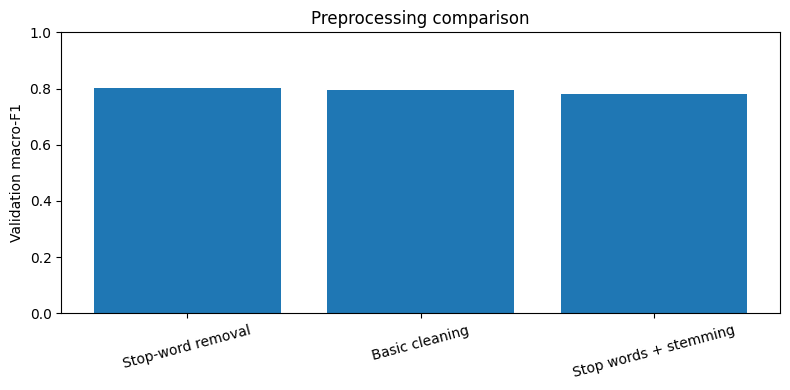

Interpretation: Stop-word removal gave the highest validation macro-F1.


In [11]:
ablation_table = pd.DataFrame({
    "preprocessing": list(ablation_scores.keys()),
    "validation_macro_f1": list(ablation_scores.values())
}).sort_values("validation_macro_f1", ascending=False)

display(ablation_table.round(4))

plt.figure(figsize=(8, 4))
plt.bar(ablation_table["preprocessing"], ablation_table["validation_macro_f1"])
plt.title("Preprocessing comparison")
plt.ylabel("Validation macro-F1")
plt.xticks(rotation=15)
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

print("Interpretation:", best_version, "gave the highest validation macro-F1.")

### 5.3 Apply the selected preprocessing

Use the selected version for all three data splits.

In [12]:
if best_version == "Basic cleaning":
    train_clean = train_basic
    val_clean = val_basic
    final_remove_stop = False
    final_use_stem = False
elif best_version == "Stop-word removal":
    train_clean = train_stop
    val_clean = val_stop
    final_remove_stop = True
    final_use_stem = False
else:
    train_clean = train_stem
    val_clean = val_stem
    final_remove_stop = True
    final_use_stem = True

test_clean = [
    preprocess(text, remove_stop=final_remove_stop, use_stem=final_use_stem)
    for text in X_test
]

print("Original text:")
print(X_train.iloc[0][:250])
print("\nCleaned text:")
print(train_clean[0][:250])

Original text:
Quality, Environment & Sustainability Practitioner Aurecon provides world-class engineering, management and specialist technical services for government and private sector clients globally. Our vision is to foster human achievement and our partnershi

Cleaned text:
quality environment sustainability practitioner aurecon provides world class engineering management specialist technical services government private sector clients globally vision foster human achievement partnerships clients make daily difference co


### 5.4 Common words after preprocessing

Print the most common words in each class after applying the selected cleaning method.

In [13]:
clean_train_df = pd.DataFrame({
    "label": y_train.values,
    "clean_text": train_clean
})

clean_top_words = get_frequent_words(clean_train_df, "clean_text")

for label in class_order:
    print("\n", label, "— after preprocessing")
    print(clean_top_words[label])


 IT — after preprocessing
[('experience', 3280), ('business', 2118), ('skills', 1562), ('team', 1450), ('role', 1435), ('work', 1324), ('project', 1321), ('management', 1268), ('development', 1079), ('support', 1028), ('working', 1015), ('technical', 968)]

 Finance — after preprocessing
[('role', 1813), ('business', 1547), ('team', 1526), ('experience', 1526), ('financial', 1260), ('skills', 1209), ('work', 1074), ('management', 883), ('apply', 761), ('client', 748), ('accounting', 730), ('working', 707)]

 Marketing — after preprocessing
[('marketing', 1050), ('experience', 659), ('role', 512), ('team', 441), ('skills', 415), ('work', 393), ('business', 367), ('media', 363), ('management', 309), ('digital', 302), ('working', 293), ('manager', 286)]

 Education — after preprocessing
[('school', 1612), ('learning', 1183), ('students', 1111), ('teaching', 1026), ('s', 930), ('work', 913), ('education', 889), ('student', 834), ('children', 789), ('skills', 773), ('experience', 741), ('s

This chart compares the most common words in the training text before and after cleaning.

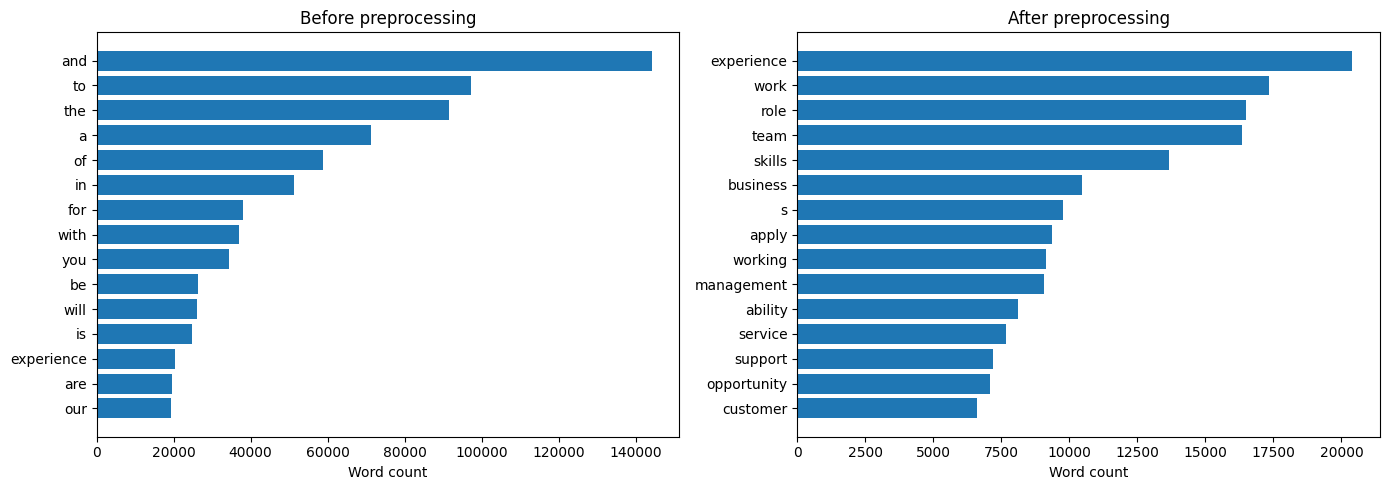

Interpretation: cleaning removes common function words and leaves more job-related terms.


In [14]:
raw_words = Counter(re.findall(r"[a-z]+", " ".join(X_train).lower())).most_common(15)
clean_words = Counter(re.findall(r"[a-z]+", " ".join(train_clean).lower())).most_common(15)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

words, counts = zip(*raw_words)
axes[0].barh(list(words)[::-1], list(counts)[::-1])
axes[0].set_title("Before preprocessing")
axes[0].set_xlabel("Word count")

words, counts = zip(*clean_words)
axes[1].barh(list(words)[::-1], list(counts)[::-1])
axes[1].set_title("After preprocessing")
axes[1].set_xlabel("Word count")

plt.tight_layout()
plt.show()
print("Interpretation: cleaning removes common function words and leaves more job-related terms.")

## 6. Text representations

Create BoW, TF-IDF and average Word2Vec features. Fit the vectorisers and Word2Vec model on training text only.

### 6.1 Choose the TF-IDF n-gram setting

Compare unigram TF-IDF with unigram-plus-bigram TF-IDF using validation macro-F1.

In [15]:
ngram_scores = {}

for ngram in [(1, 1), (1, 2)]:
    vectorizer = TfidfVectorizer(
        ngram_range=ngram,
        max_features=15000,
        min_df=3,
        sublinear_tf=True,
        dtype=np.float32
    )
    train_matrix = vectorizer.fit_transform(train_clean)
    val_matrix = vectorizer.transform(val_clean)

    model = LogisticRegression(
        C=1.0, max_iter=1000, class_weight="balanced",
        random_state=SEED
    )
    model.fit(train_matrix, y_train)
    prediction = model.predict(val_matrix)

    score = f1_score(y_val, prediction, average="macro", zero_division=0)
    ngram_scores[ngram] = score
    print("TF-IDF", ngram, "validation macro-F1:", round(score, 4))

best_ngram = max(ngram_scores, key=ngram_scores.get)
print("Selected n-gram range:", best_ngram)

TF-IDF (1, 1) validation macro-F1: 0.8021
TF-IDF (1, 2) validation macro-F1: 0.8082
Selected n-gram range: (1, 2)


### 6.2 Build BoW and TF-IDF

Fit each vectoriser on training documents. Use it to transform validation and test documents.

In [16]:
bow_vectorizer = CountVectorizer(max_features=15000, min_df=3, dtype=np.float32)
tfidf_vectorizer = TfidfVectorizer(
    ngram_range=best_ngram,
    max_features=15000,
    min_df=3,
    sublinear_tf=True,
    dtype=np.float32
)

X_train_bow = bow_vectorizer.fit_transform(train_clean)
X_val_bow = bow_vectorizer.transform(val_clean)
X_test_bow = bow_vectorizer.transform(test_clean)

X_train_tfidf = tfidf_vectorizer.fit_transform(train_clean)
X_val_tfidf = tfidf_vectorizer.transform(val_clean)
X_test_tfidf = tfidf_vectorizer.transform(test_clean)

print("BoW training shape:", X_train_bow.shape)
print("TF-IDF training shape:", X_train_tfidf.shape)

BoW training shape: (9683, 13632)
TF-IDF training shape: (9683, 15000)


### 6.3 Build average Word2Vec

Train Word2Vec on the training documents only. Each job advertisement is represented by the average of its known word vectors.

In [17]:
train_tokens = [text.split() for text in train_clean]

word2vec_model = Word2Vec(
    sentences=train_tokens,
    vector_size=100,
    window=5,
    min_count=2,
    workers=1,
    sg=1,
    epochs=5,
    seed=SEED
)

def average_vectors(documents):
    all_vectors = []

    for document in documents:
        word_vectors = []

        for word in document.split():
            if word in word2vec_model.wv:
                word_vectors.append(word2vec_model.wv[word])

        if len(word_vectors) > 0:
            document_vector = np.mean(word_vectors, axis=0)
        else:
            document_vector = np.zeros(100)

        all_vectors.append(document_vector)

    return np.array(all_vectors)

X_train_w2v = average_vectors(train_clean)
X_val_w2v = average_vectors(val_clean)
X_test_w2v = average_vectors(test_clean)

print("Word2Vec vocabulary size:", len(word2vec_model.wv))
print("Word2Vec training shape:", X_train_w2v.shape)

Word2Vec vocabulary size: 19838
Word2Vec training shape: (9683, 100)


## 7. Classifiers and tuning

Use a majority-class baseline, Multinomial Naive Bayes on BoW and TF-IDF, and Logistic Regression on all three representations. Choose `alpha` and `C` with validation macro-F1.

In [18]:
def get_metrics(actual, predicted):
    return {
        "accuracy": accuracy_score(actual, predicted),
        "macro_precision": precision_score(actual, predicted, average="macro", zero_division=0),
        "macro_recall": recall_score(actual, predicted, average="macro", zero_division=0),
        "macro_f1": f1_score(actual, predicted, average="macro", zero_division=0)
    }

# Store the training and validation features for each representation.
train_features = {
    "BoW": X_train_bow,
    "TF-IDF": X_train_tfidf,
    "Word2Vec average": X_train_w2v
}
val_features = {
    "BoW": X_val_bow,
    "TF-IDF": X_val_tfidf,
    "Word2Vec average": X_val_w2v
}
test_features = {
    "BoW": X_test_bow,
    "TF-IDF": X_test_tfidf,
    "Word2Vec average": X_test_w2v
}

validation_results = []
selected_models = {}

# Majority baseline: always predict the most common training class.
majority_class = y_train.value_counts().idxmax()
baseline_prediction = [majority_class] * len(y_val)
validation_results.append({
    "model": "Majority baseline",
    "best_parameter": "None",
    **get_metrics(y_val, baseline_prediction)
})

print("Majority class:", majority_class)

# Tune Naive Bayes alpha for BoW and TF-IDF.
for representation in ["BoW", "TF-IDF"]:
    best_score = -1
    best_model = None
    best_alpha = None

    for alpha in [0.1, 0.5, 1.0, 2.0]:
        model = MultinomialNB(alpha=alpha)
        model.fit(train_features[representation], y_train)
        prediction = model.predict(val_features[representation])
        score = f1_score(y_val, prediction, average="macro", zero_division=0)

        if score > best_score:
            best_score = score
            best_model = model
            best_alpha = alpha

    model_name = "MultinomialNB | " + representation
    selected_models[model_name] = best_model

    validation_results.append({
        "model": model_name,
        "best_parameter": "alpha=" + str(best_alpha),
        **get_metrics(y_val, best_model.predict(val_features[representation]))
    })

# Tune Logistic Regression C for BoW, TF-IDF and Word2Vec.
for representation in ["BoW", "TF-IDF", "Word2Vec average"]:
    best_score = -1
    best_model = None
    best_c = None

    for c_value in [0.1, 1.0, 5.0]:
        model = LogisticRegression(
            C=c_value,
            max_iter=1000,
            class_weight="balanced",
            random_state=SEED
        )
        model.fit(train_features[representation], y_train)
        prediction = model.predict(val_features[representation])
        score = f1_score(y_val, prediction, average="macro", zero_division=0)

        if score > best_score:
            best_score = score
            best_model = model
            best_c = c_value

    model_name = "LogisticRegression | " + representation
    selected_models[model_name] = best_model

    validation_results.append({
        "model": model_name,
        "best_parameter": "C=" + str(best_c),
        **get_metrics(y_val, best_model.predict(val_features[representation]))
    })

validation_table = pd.DataFrame(validation_results)
validation_table = validation_table.sort_values("macro_f1", ascending=False).reset_index(drop=True)
display(validation_table.round(4))

print("The first row has the highest validation macro-F1.")

,model,best_parameter,accuracy,macro_precision,macro_recall,macro_f1
0,LogisticRegression | TF-IDF,C=5.0,0.9190,0.7932,0.8786,0.8300
1,MultinomialNB | TF-IDF,alpha=0.1,0.9094,0.8190,0.7908,0.8031
2,MultinomialNB | BoW,alpha=2.0,0.8978,0.7738,0.8307,0.7998
3,LogisticRegression | BoW,C=0.1,0.9060,0.7730,0.8285,0.7978
4,LogisticRegression | Word2Vec average,C=5.0,0.8289,0.6386,0.8832,0.7137
5,Majority baseline,None,0.7383,0.1231,0.1667,0.1416


Majority class: Other
The first row has the highest validation macro-F1.


## 8. Final test results

The model settings are now fixed. Evaluate each final model on the test set and compare the required metrics.

In [19]:
test_results_rows = []
test_predictions = {}

# Evaluate the majority baseline on the test set.
baseline_test_prediction = [majority_class] * len(y_test)
test_predictions["Majority baseline"] = baseline_test_prediction
test_results_rows.append({
    "model": "Majority baseline",
    **get_metrics(y_test, baseline_test_prediction)
})

# Evaluate each tuned model once on the test set.
for model_name in selected_models:
    representation = model_name.split(" | ")[1]
    model = selected_models[model_name]

    prediction = model.predict(test_features[representation])
    test_predictions[model_name] = prediction

    test_results_rows.append({
        "model": model_name,
        **get_metrics(y_test, prediction)
    })

test_results = pd.DataFrame(test_results_rows)
display(test_results.round(4))

,model,accuracy,macro_precision,macro_recall,macro_f1
0,Majority baseline,0.7378,0.1230,0.1667,0.1415
1,MultinomialNB | BoW,0.9089,0.7775,0.8319,0.8023
2,MultinomialNB | TF-IDF,0.9171,0.8338,0.7911,0.8097
3,LogisticRegression | BoW,0.9142,0.7850,0.8495,0.8136
4,LogisticRegression | TF-IDF,0.9239,0.8044,0.8765,0.8365
5,LogisticRegression | Word2Vec average,0.8352,0.6434,0.8889,0.7185


### 8.1 Best model and confusion matrix

Choose the best model from the validation table, then show its test results and confusion matrix.

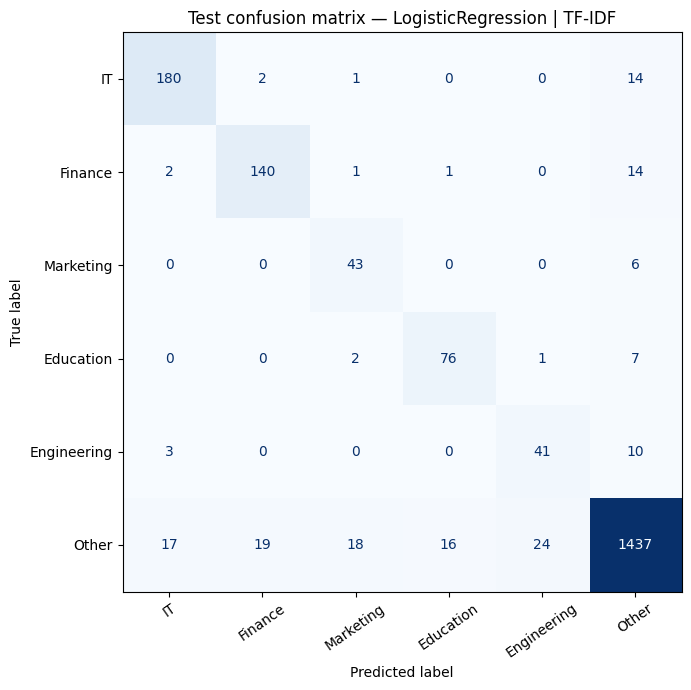

Best model: LogisticRegression | TF-IDF
Validation macro-F1: 0.83

Test classification report:
              precision    recall  f1-score   support

          IT       0.89      0.91      0.90       197
     Finance       0.87      0.89      0.88       158
   Marketing       0.66      0.88      0.75        49
   Education       0.82      0.88      0.85        86
 Engineering       0.62      0.76      0.68        54
       Other       0.97      0.94      0.95      1531

    accuracy                           0.92      2075
   macro avg       0.80      0.88      0.84      2075
weighted avg       0.93      0.92      0.93      2075



In [20]:
best_model_name = validation_table.loc[0, "model"]
best_prediction = test_predictions[best_model_name]

print("Best model:", best_model_name)
print("Validation macro-F1:", round(validation_table.loc[0, "macro_f1"], 4))
print("\nTest classification report:")
print(classification_report(y_test, best_prediction, labels=class_order, zero_division=0))

cm = confusion_matrix(y_test, best_prediction, labels=class_order)

display_plot = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_order
)
fig, ax = plt.subplots(figsize=(9, 7))
display_plot.plot(ax=ax, cmap="Blues", xticks_rotation=35, colorbar=False)
plt.title("Test confusion matrix — " + best_model_name)
plt.tight_layout()
plt.show()

## 9. Informative words from Naive Bayes

For each class, show the ten words with the largest log-probability ratio in the BoW Naive Bayes model.

In [21]:
nb_bow = selected_models["MultinomialNB | BoW"]
feature_names = bow_vectorizer.get_feature_names_out()
log_probabilities = nb_bow.feature_log_prob_
class_names = nb_bow.classes_

for class_index in range(len(class_names)):
    class_name = class_names[class_index]

    # Compare this class with the average log probability of the other classes.
    other_class_indexes = [i for i in range(len(class_names)) if i != class_index]
    other_average = log_probabilities[other_class_indexes].mean(axis=0)
    log_ratio = log_probabilities[class_index] - other_average

    top_indexes = np.argsort(log_ratio)[-10:][::-1]

    print("\n", class_name, "— 10 informative words")
    for index in top_indexes:
        print(feature_names[index], round(log_ratio[index], 3))


 Education — 10 informative words
classroom 5.497
teachers 5.392
teacher 5.371
teaching 5.254
students 4.762
school 4.576
curriculum 4.56
det 4.485
sc 4.46
childhood 4.409

 Engineering — 10 informative words
engineer 4.24
structural 4.03
civil 3.841
mechanical 3.678
electrical 3.664
drawings 3.29
highways 3.213
drafter 3.167
cad 3.146
autocad 3.136

 Finance — 10 informative words
accountant 4.719
tax 4.49
payable 4.137
payroll 4.062
cpa 4.026
accounting 3.977
reconciliations 3.904
ca 3.887
receivable 3.658
finance 3.491

 IT — 10 informative words
java 4.324
developer 4.015
javascript 3.962
cutover 3.943
cisco 3.871
aws 3.804
stack 3.68
server 3.676
api 3.653
azure 3.499

 Marketing — 10 informative words
campaigns 3.979
cr 3.962
seo 3.89
campaign 3.845
marketing 3.783
media 3.739
sem 3.335
content 3.176
pr 3.049
collateral 3.045

 Other — 10 informative words
forklift 3.592
nurse 2.977
store 2.931
nursing 2.892
truck 2.763
ahpra 2.703
nurses 2.634
chef 2.603
mechanic 2.553
shifts 2

## 10. Error analysis

Show 20 misclassified test examples from the model selected using validation data. The notes below group the examples by the main reason for the mistake.

In [22]:
error_table = pd.DataFrame({
    "source_row_id": df.loc[test_idx, "source_row_id"].values,
    "text": X_test.values,
    "true_label": y_test.values,
    "predicted_label": best_prediction
})

errors = error_table[error_table["true_label"] != error_table["predicted_label"]].copy()

print("Misclassified test documents:", len(errors))
assert len(errors) >= 20, "There must be at least 20 misclassified examples for review."

display(errors.head(20)[
    ["source_row_id", "true_label", "predicted_label", "text"]
].assign(text=lambda table: table["text"].str[:350]).reset_index(drop=True))

,source_row_id,true_label,predicted_label,text
0,13761,Other,Engineering,Production/Quality Engineer Position Descripti...
1,6763,Other,Engineering,Maintenance Team Lead Fitter ACRWORLD are work...
2,1227,Engineering,Other,Safety Assurance Engineer - Laing O'Rourke - S...
3,13797,Other,Finance,Corporate Funds - 3yrs to SA Our client is one...
4,3944,Marketing,Other,Research Assistant Property Daily is published...
5,9249,Other,Education,RTO Educator - Kimberley Aboriginal Medical Se...
6,8085,IT,Other,Inside Sales Account Manager At Hewlett Packar...
7,7413,Other,IT,Change Analyst About the role Change analyst t...
8,7069,IT,Other,Database Assistant - Part Time Historical pers...
9,6494,IT,Other,Cable Hauler - (DAS) Kordia is one of Australi...


Misclassified test documents: 158


### 10.1 Review the error types

These notes describe the first 20 errors shown above. The category counts give a short summary of the review.

In [23]:
# Each note is linked to the original row number in the CSV.
error_notes = {
    13761: ("Broad Other grouping", "The source category is Manufacturing, Transport & Logistics, but the title and duties describe a production or quality engineer. The work overlaps with Engineering."),
    6763: ("Broad Other grouping", "The source category is Trades & Services. The role supervises fitters and electricians and maintains refrigeration equipment, which overlaps with mechanical engineering."),
    1227: ("Generic recruitment/project language", "The title is Safety Assurance Engineer. Construction, safety and risk terms also appear in many other job advertisements."),
    13797: ("Overlapping job functions", "The source category is Legal, but the role is a lawyer working with corporate funds and financial services. These terms overlap with Finance."),
    3944: ("Potential source-label ambiguity", "The source category is Marketing & Communications, but the title is Research Assistant and the duties focus on property-market research and administration."),
    9249: ("Overlapping job functions", "The source category is Healthcare & Medical, while the title is RTO Educator. The training duties overlap with Education."),
    8085: ("Overlapping job functions", "The source category is IT, but the position is mainly inside sales and account management for technology products."),
    7413: ("Overlapping job functions", "The source category is Consulting & Strategy. The change analyst works with digital tools and data-science projects, so the text overlaps with IT."),
    7069: ("Overlapping job functions", "The source category is IT, but the role mainly involves records, a membership database and administration."),
    6494: ("Overlapping job functions", "The source category is IT, but the role involves cable installation and field work, which overlaps with Trades & Services."),
    24: ("Potential source-label ambiguity", "The source category is IT, but the business-development role is mostly about enterprise sales and customer relationships."),
    9997: ("Insufficient context", "Only the title Kindergarten Improvement Advisor is available. The description is empty, so there is little text to classify."),
    11768: ("Overlapping job functions", "The source category is Banking & Financial Services, but the description includes advertising, marketing and promotional work."),
    3927: ("Overlapping job functions", "The source category is Human Resources & Recruitment, while the instructional designer creates training and learning materials."),
    2792: ("Potential source-label ambiguity", "The source category is Real Estate & Property, but the title is Shopping Centre Marketing Manager and the duties are marketing-related."),
    14945: ("Overlapping job functions", "The source category is Trades & Services. The nanny role includes school pick-up and homework support, which adds education-related terms."),
    1284: ("Overlapping job functions", "The source category is IT, but the role also includes council, leadership and customer-service responsibilities."),
    14233: ("Potential source-label ambiguity", "The source category is IT, but the role focuses on financial-crime investigations, KYC and regulatory reporting."),
    13011: ("Overlapping job functions", "The source category is Design & Architecture, while the UX/UI role also requires HTML, CSS and digital-product skills."),
    7887: ("Overlapping job functions", "The source category is Design & Architecture, but the title combines web design with digital marketing. The duties include website design, HTML, CSS, SEO and campaign work, so the text overlaps with Marketing.")
}

review_errors = errors.head(20).copy()
error_types = []
review_notes = []

for row_id in review_errors["source_row_id"]:
    if row_id in error_notes:
        error_types.append(error_notes[row_id][0])
        review_notes.append(error_notes[row_id][1])
    else:
        error_types.append("Needs manual review")
        review_notes.append("Review this advertisement and add a short explanation.")

review_errors["error_type"] = error_types
review_errors["review_note"] = review_notes

print("Reviewed examples:", sum(review_errors["error_type"] != "Needs manual review"), "/", len(review_errors))
assert (review_errors["error_type"] != "Needs manual review").all(), "One or more examples need a manual review."

display(review_errors[
    ["source_row_id", "true_label", "predicted_label", "error_type", "review_note"]
].reset_index(drop=True))

print("Error category counts:")
display(review_errors["error_type"].value_counts().to_frame("count"))

print("Interpretation: many errors come from overlapping job duties or broad source categories.")

,source_row_id,true_label,predicted_label,error_type,review_note
0,13761,Other,Engineering,Broad Other grouping,"The source category is Manufacturing, Transpor..."
1,6763,Other,Engineering,Broad Other grouping,The source category is Trades & Services. The ...
2,1227,Engineering,Other,Generic recruitment/project language,The title is Safety Assurance Engineer. Constr...
3,13797,Other,Finance,Overlapping job functions,"The source category is Legal, but the role is ..."
4,3944,Marketing,Other,Potential source-label ambiguity,The source category is Marketing & Communicati...
5,9249,Other,Education,Overlapping job functions,"The source category is Healthcare & Medical, w..."
6,8085,IT,Other,Overlapping job functions,"The source category is IT, but the position is..."
7,7413,Other,IT,Overlapping job functions,The source category is Consulting & Strategy. ...
8,7069,IT,Other,Overlapping job functions,"The source category is IT, but the role mainly..."
9,6494,IT,Other,Overlapping job functions,"The source category is IT, but the role involv..."


,count
error_type,
Overlapping job functions,12
Potential source-label ambiguity,4
Broad Other grouping,2
Generic recruitment/project language,1
Insufficient context,1


Reviewed examples: 20 / 20
Error category counts:
Interpretation: many errors come from overlapping job duties or broad source categories.


## 11. Results and limitations

The summary below shows the selected preprocessing, TF-IDF setting, best model and largest class confusions.

In [24]:
print("Selected preprocessing:", best_version)
print("Selected TF-IDF n-gram range:", best_ngram)
print("Best model:", best_model_name)
print("Validation macro-F1:", round(float(validation_table.loc[0, "macro_f1"]), 4))

print("\nBest model test metrics:")
display(test_results[test_results["model"] == best_model_name].round(4))

# Find the largest mistakes outside the diagonal of the confusion matrix.
confusion_pairs = []

for true_index in range(len(class_order)):
    for predicted_index in range(len(class_order)):
        if true_index != predicted_index and cm[true_index, predicted_index] > 0:
            confusion_pairs.append((
                class_order[true_index],
                class_order[predicted_index],
                cm[true_index, predicted_index]
            ))

confusion_pairs = sorted(confusion_pairs, key=lambda item: item[2], reverse=True)
display(pd.DataFrame(
    confusion_pairs[:10],
    columns=["true_class", "predicted_class", "count"]
))

print("\nLimitations:")
print("- The Other class combines many different job sectors.")
print("- Some advertisements have short or missing descriptions.")
print("- Average Word2Vec does not keep word order.")
print("- The dataset licence still needs confirmation.")

,model,accuracy,macro_precision,macro_recall,macro_f1
4,LogisticRegression | TF-IDF,0.9239,0.8044,0.8765,0.8365


,true_class,predicted_class,count
0,Other,Engineering,24
1,Other,Finance,19
2,Other,Marketing,18
3,Other,IT,17
4,Other,Education,16
5,IT,Other,14
6,Finance,Other,14
7,Engineering,Other,10
8,Education,Other,7
9,Marketing,Other,6


Selected preprocessing: Stop-word removal
Selected TF-IDF n-gram range: (1, 2)
Best model: LogisticRegression | TF-IDF
Validation macro-F1: 0.83

Best model test metrics:

Limitations:
- The Other class combines many different job sectors.
- Some advertisements have short or missing descriptions.
- Average Word2Vec does not keep word order.
- The dataset licence still needs confirmation.


## 12. Conclusion

This project compares preprocessing, BoW, TF-IDF, average Word2Vec, Naive Bayes and Logistic Regression for job-category classification. The final model is selected with validation macro-F1, and the test set is used for the final comparison. Transformer models are not used because they are outside the midterm scope.

## 13. Reproducibility and AI use

- Raw dataset limit: 15,000 rows.
- Empty documents and exact duplicate text are removed.
- Random seed: `42`; split: stratified 70/15/15.
- Vectorisers and Word2Vec are fitted on training documents only.
- Model settings are selected using validation macro-F1.
- Dataset source: the public CSV linked in Section 1.
- Dataset licence: not confirmed; obtain permission or verify the licence before submission.
- AI use: ChatGPT was used to help review, debug and edit code and notebook wording. Add the relevant shareable conversation link or an exported conversation log to the report appendix, as required by the course.